<a href="https://colab.research.google.com/github/n1m1nd33p/Practical-ML/blob/main/Decision_Tree_Iris_Practical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning Lab – Practical 8: Decision Tree Classification

  


## Objectives
1. Train and visualize a Decision Tree classifier.
2. Study the effect of tree depth and splitting criteria.




In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv("Iris_Decision_Tree_Dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Dataset loaded successfully!
Dataset shape: (150, 5)

First five rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Column names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species']

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


In [ ]:
target_column = "species"

X = df.drop(columns=[target_column])
y = df[target_column]

print("Input features:", X.columns.tolist())
print("\nTarget classes:", sorted(y.unique()))
print("\nClass distribution:")
print(y.value_counts())

In [ ]:
X = df.drop(columns=['species'])
y = df['species']

print("Features created successfully!")
print("X shape:", X.shape)
print("y shape:", y.shape)

Features created successfully!
X shape: (150, 4)
y shape: (150,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 120
Testing samples: 30


In [ ]:
tree_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

tree_model.fit(X_train, y_train)
y_pred = tree_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Decision Tree Accuracy: {accuracy * 100:.2f}%")

Decision Tree Accuracy: 96.67%


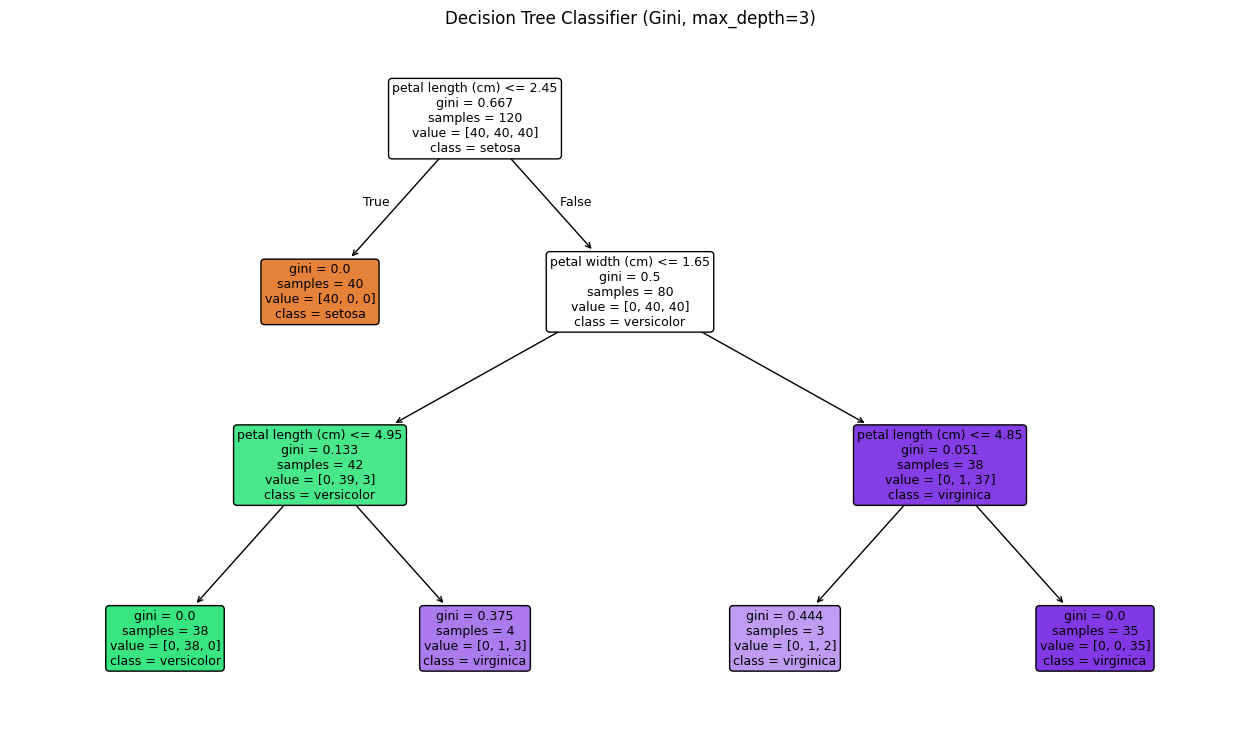

In [ ]:
plt.figure(figsize=(16, 9))
plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=tree_model.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Decision Tree Classifier (Gini, max_depth=3)")
plt.show()

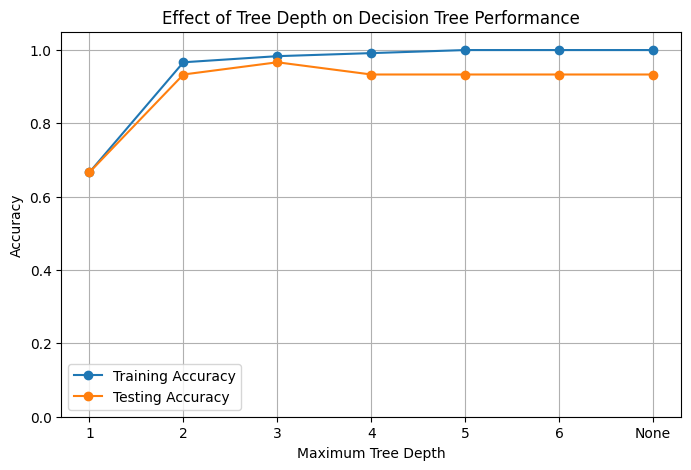

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(depth_df["max_depth"], depth_df["training_accuracy"],
         marker="o", label="Training Accuracy")
plt.plot(depth_df["max_depth"], depth_df["testing_accuracy"],
         marker="o", label="Testing Accuracy")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Effect of Tree Depth on Decision Tree Performance")
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
criteria = ["gini", "entropy", "log_loss"]
criterion_results = []

for criterion in criteria:
    model = DecisionTreeClassifier(
        criterion=criterion,
        max_depth=3,
        random_state=42
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    criterion_results.append({
        "criterion": criterion,
        "testing_accuracy": accuracy_score(y_test, predictions),
        "tree_depth": model.get_depth(),
        "number_of_leaves": model.get_n_leaves()
    })

criterion_df = pd.DataFrame(criterion_results)
display(criterion_df)

,criterion,testing_accuracy,tree_depth,number_of_leaves
0,gini,0.966667,3,5
1,entropy,0.966667,3,5
2,log_loss,0.966667,3,5


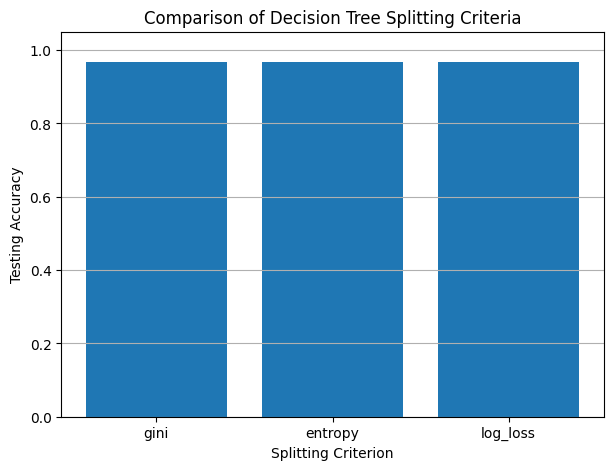

In [ ]:
plt.figure(figsize=(7, 5))
plt.bar(criterion_df["criterion"], criterion_df["testing_accuracy"])
plt.xlabel("Splitting Criterion")
plt.ylabel("Testing Accuracy")
plt.title("Comparison of Decision Tree Splitting Criteria")
plt.ylim(0, 1.05)
plt.grid(axis="y")
plt.show()

,Feature,Importance
2,petal length (cm),0.579077
3,petal width (cm),0.420923
1,sepal width (cm),0.000000
0,sepal length (cm),0.000000


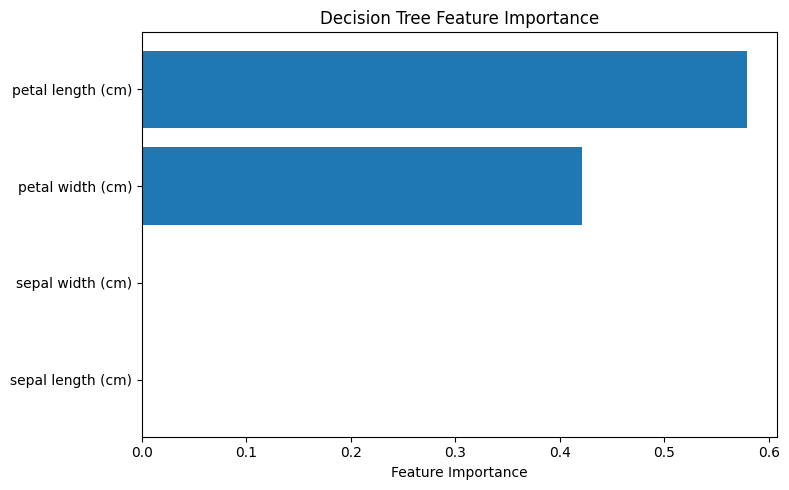

In [ ]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": tree_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

display(importance)

plt.figure(figsize=(8, 5))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Feature Importance")
plt.title("Decision Tree Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
print("========== FINAL RESULTS ==========")
print("Algorithm: Decision Tree Classifier")
print("Dataset: Iris Flower Dataset")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Basic model criterion: gini")
print("Basic model max_depth: 3")
print(f"Basic model test accuracy: {accuracy * 100:.2f}%")

print("\nTree depth comparison:")
display(depth_df)

print("\nSplitting criterion comparison:")
display(criterion_df)

print("Practical completed successfully!")

========== FINAL RESULTS ==========
Algorithm: Decision Tree Classifier
Dataset: Iris Flower Dataset
Training samples: 120
Testing samples: 30
Basic model criterion: gini
Basic model max_depth: 3
Basic model test accuracy: 96.67%

Tree depth comparison:


,max_depth,training_accuracy,testing_accuracy
0,1,0.666667,0.666667
1,2,0.966667,0.933333
2,3,0.983333,0.966667
3,4,0.991667,0.933333
4,5,1.000000,0.933333
5,6,1.000000,0.933333
6,None,1.000000,0.933333



Splitting criterion comparison:


,criterion,testing_accuracy,tree_depth,number_of_leaves
0,gini,0.966667,3,5
1,entropy,0.966667,3,5
2,log_loss,0.966667,3,5


Practical completed successfully!
